In [4]:
import pandas as pd

# Load the dataset
file_path = '/content/lahore_house_listings_zameen.csv'
df = pd.read_csv(file_path)

# Display basic dataset details and preview the first few rows
print(f"Dataset shape: {df.shape}")
print("\nDataset Columns:")
print(df.info())

display(df.head())

Dataset shape: (18249, 23)

Dataset Columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Title                18249 non-null  object 
 1   Location             18249 non-null  object 
 2   Type                 18249 non-null  object 
 3   Price                18249 non-null  object 
 4   Area                 18249 non-null  object 
 5   Bedrooms             18249 non-null  object 
 6   Bathrooms            18249 non-null  object 
 7   Purpose              18249 non-null  object 
 8   Date Posted          11319 non-null  object 
 9   Built Year           13497 non-null  float64
 10  Kitchens             18249 non-null  int64  
 11  Store Rooms          18249 non-null  int64  
 12  Servant Quarters     18249 non-null  int64  
 13  Furnished            18249 non-null  bool   
 14  Gym                  18249 non-null  bool

,Title,Location,Type,Price,Area,Bedrooms,Bathrooms,Purpose,Date Posted,Built Year,...,Furnished,Gym,Study Room,Drawing Room,Dining Room,Lawn/Garden,Swimming Pool,Electricity Backup,Lounge/Sitting Room,Link
0,ACTUALLY 25 MARLA DOUBLE UNIT LUXURIOUS & GRAC...,"DHA Phase 6 - Block F, DHA Phase 6, DHA Defenc...",House,8.15 Crore,1 Kanal,6,7,For Sale,2025-07-27,2024.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_phase_6_dh...
1,3 Years Installment Plan Luxury Brand New Hous...,"Park View City, Lahore, Punjab",House,1.5 Crore,5 Marla,4,5,For Sale,2025-07-25,2012.0,...,True,False,False,True,True,True,False,True,True,https://www.zameen.com/Property/lahore_park_vi...
2,5 Marla Luxury House In Rose Block Of Park-Vie...,"Park View City - Rose Block, Park View City, L...",House,2.4 Crore,5 Marla,4,4,For Sale,2025-07-25,2025.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/park_view_city...
3,Full Basement 1 kanal Brand New Luxury House N...,"DHA Phase 7 - Block S, DHA Phase 7, DHA Defenc...",House,7.5 Crore,1 Kanal,5,6,For Sale,2025-07-25,2024.0,...,False,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_phase_7_dh...
4,1 Kanal Dream Home With Private Pool In DHA Ph...,"DHA Phase 6, DHA Defence, Lahore, Punjab",House,6.95 Crore,1 Kanal,6,7,For Sale,2025-07-25,2024.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_defence_dh...


### Data Cleaning: Standardize Price and Area
We will convert `Price` to Millions PKR and convert `Area` to Marla numeric units.

In [7]:
import re
import numpy as np

def clean_price(price_str):
    if pd.isna(price_str):
        return np.nan
    price_str = str(price_str).lower().strip()
    # Convert Crore (10 Million) to Millions
    if 'crore' in price_str:
        val = float(re.findall(r'\d+\.?\d*', price_str)[0])
        return val * 10.0
    # Convert Lakh (0.1 Million) to Millions
    elif 'lakh' in price_str:
        val = float(re.findall(r'\d+\.?\d*', price_str)[0])
        return val * 0.1
    # Convert Thousand to Millions
    elif 'thousand' in price_str:
        val = float(re.findall(r'\d+\.?\d*', price_str)[0])
        return val * 0.001
    else:
        try:
            nums = re.findall(r'\d+\.?\d*', price_str)
            return float(nums[0]) / 1000000 if nums else np.nan
        except:
            return np.nan

def clean_area(area_str):
    if pd.isna(area_str):
        return np.nan
    area_str = str(area_str).lower().strip()
    try:
        num = float(re.findall(r'\d+\.?\d*', area_str)[0])
        if 'kanal' in area_str:
            return num * 20.0  # 1 Kanal = 20 Marla
        return num
    except:
        return np.nan

# Extract specific neighborhood instead of the generic city name
def extract_neighborhood(loc_str):
    if pd.isna(loc_str):
        return 'Unknown'
    parts = [p.strip() for p in str(loc_str).split(',')]
    # Typically format is: Sector/Block, Phase/Society, Lahore, Punjab
    # We look for the part before 'Lahore'
    for i, part in enumerate(parts):
        if 'lahore' in part.lower() and i > 0:
            return parts[i-1]
    return parts[0]

# Apply cleaning functions
df['Price_Millions_PKR'] = df['Price'].apply(clean_price)
df['Area_Marla'] = df['Area'].apply(clean_area)
df['General_Location'] = df['Location'].apply(extract_neighborhood)

display(df[['Location', 'General_Location', 'Price', 'Price_Millions_PKR', 'Area', 'Area_Marla']].head())

,Location,General_Location,Price,Price_Millions_PKR,Area,Area_Marla
0,"DHA Phase 6 - Block F, DHA Phase 6, DHA Defenc...",DHA Defence,8.15 Crore,81.5,1 Kanal,20.0
1,"Park View City, Lahore, Punjab",Park View City,1.5 Crore,15.0,5 Marla,5.0
2,"Park View City - Rose Block, Park View City, L...",Park View City,2.4 Crore,24.0,5 Marla,5.0
3,"DHA Phase 7 - Block S, DHA Phase 7, DHA Defenc...",DHA Defence,7.5 Crore,75.0,1 Kanal,20.0
4,"DHA Phase 6, DHA Defence, Lahore, Punjab",DHA Defence,6.95 Crore,69.5,1 Kanal,20.0


### Visualizing Relationships with Matplotlib
Now, let's create a scatter plot of Price vs. Area, and a bar plot showing the average price by top locations.

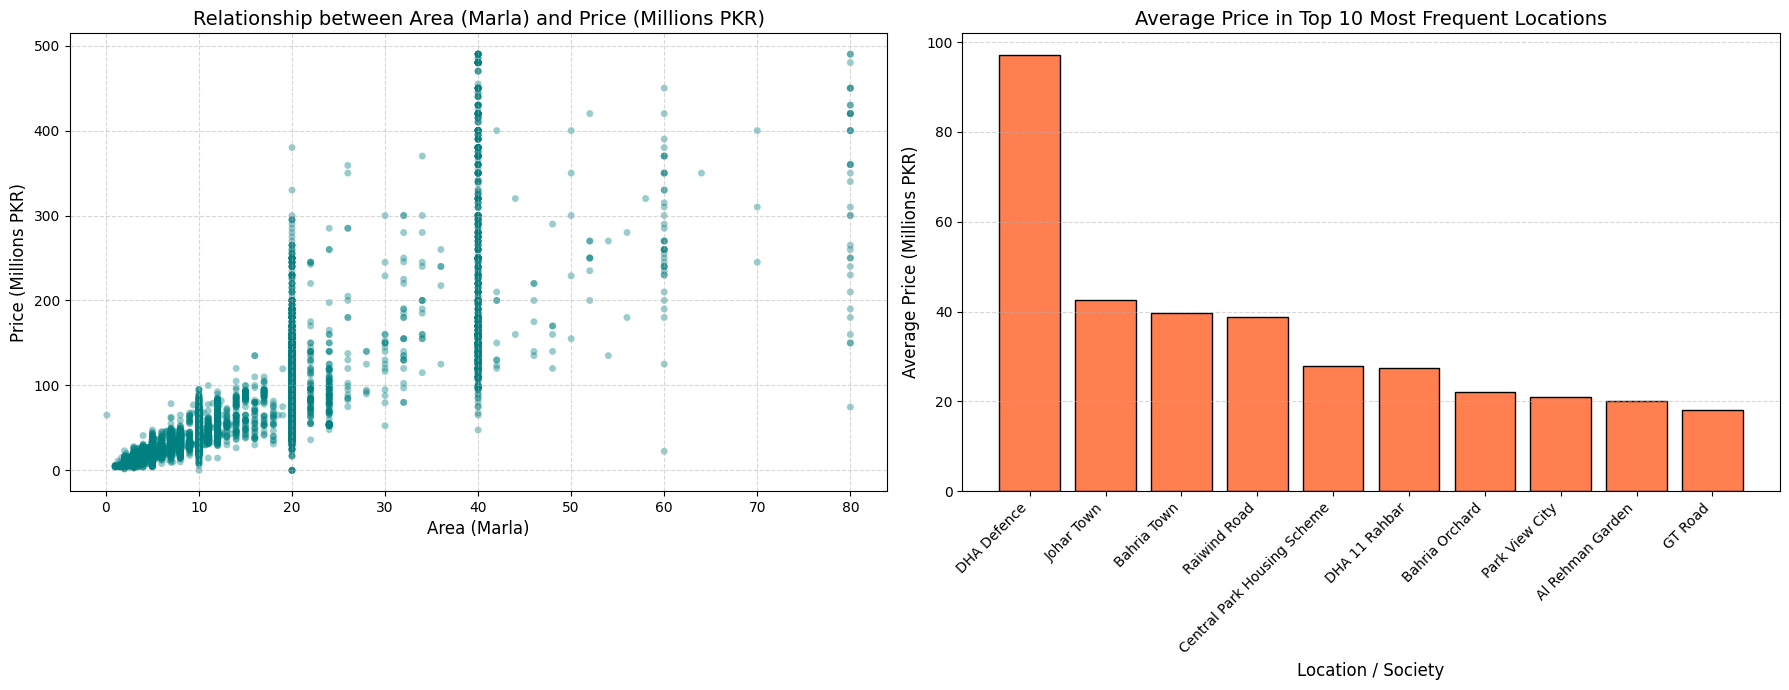

In [8]:
import matplotlib.pyplot as plt

# Filter out extreme outliers for better visualization
plot_df = df[(df['Price_Millions_PKR'] > 0) & (df['Price_Millions_PKR'] < 500) & (df['Area_Marla'] > 0) & (df['Area_Marla'] <= 80)].dropna(subset=['Price_Millions_PKR', 'Area_Marla'])

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Scatter Plot: Price vs Area
axes[0].scatter(plot_df['Area_Marla'], plot_df['Price_Millions_PKR'], alpha=0.4, color='teal', edgecolor='none', s=25)
axes[0].set_title('Relationship between Area (Marla) and Price (Millions PKR)', fontsize=14)
axes[0].set_xlabel('Area (Marla)', fontsize=12)
axes[0].set_ylabel('Price (Millions PKR)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Bar Plot: Top Locations by Avg Price
top_locations = df['General_Location'].value_counts().head(10).index
loc_stats = df[df['General_Location'].isin(top_locations)].groupby('General_Location')['Price_Millions_PKR'].mean().sort_values(ascending=False)

# Correcting set_xticklabels warnings with set_xticks
axes[1].bar(loc_stats.index, loc_stats.values, color='coral', edgecolor='k')
axes[1].set_title('Average Price in Top 10 Most Frequent Locations', fontsize=14)
axes[1].set_xlabel('Location / Society', fontsize=12)
axes[1].set_ylabel('Average Price (Millions PKR)', fontsize=12)
axes[1].set_xticks(range(len(loc_stats)))
axes[1].set_xticklabels(loc_stats.index, rotation=45, ha='right')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Exploratory Data Analysis: Bedrooms vs. Price
We will clean the `Bedrooms` column to convert it to a numeric data type, handle any invalid entries, and then visualize how the price changes with the count of bedrooms.

In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Function to clean and convert Bedrooms to float/int
def clean_bedrooms(bed_str):
    if pd.isna(bed_str):
        return np.nan
    bed_str = str(bed_str).strip()
    try:
        # Extract first numeric sequence found
        match = re.search(r'\d+', bed_str)
        return int(match.group()) if match else np.nan
    except:
        return np.nan

# Apply cleaning to Bedrooms
df['Bedrooms_Numeric'] = df['Bedrooms'].apply(clean_bedrooms)

# Check the distribution of bedrooms
print("Bedroom count distribution:")
print(df['Bedrooms_Numeric'].value_counts().sort_index())

Bedroom count distribution:
Bedrooms_Numeric
1.0       60
2.0      321
3.0     4571
4.0     3624
5.0     6813
6.0     1888
7.0      437
8.0      126
9.0       32
10.0      40
11.0      19
Name: count, dtype: int64


/tmp/ipykernel_924/3351557806.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(bedroom_groups, labels=sorted(bed_df['Bedrooms_Numeric'].unique()), patch_artist=True,


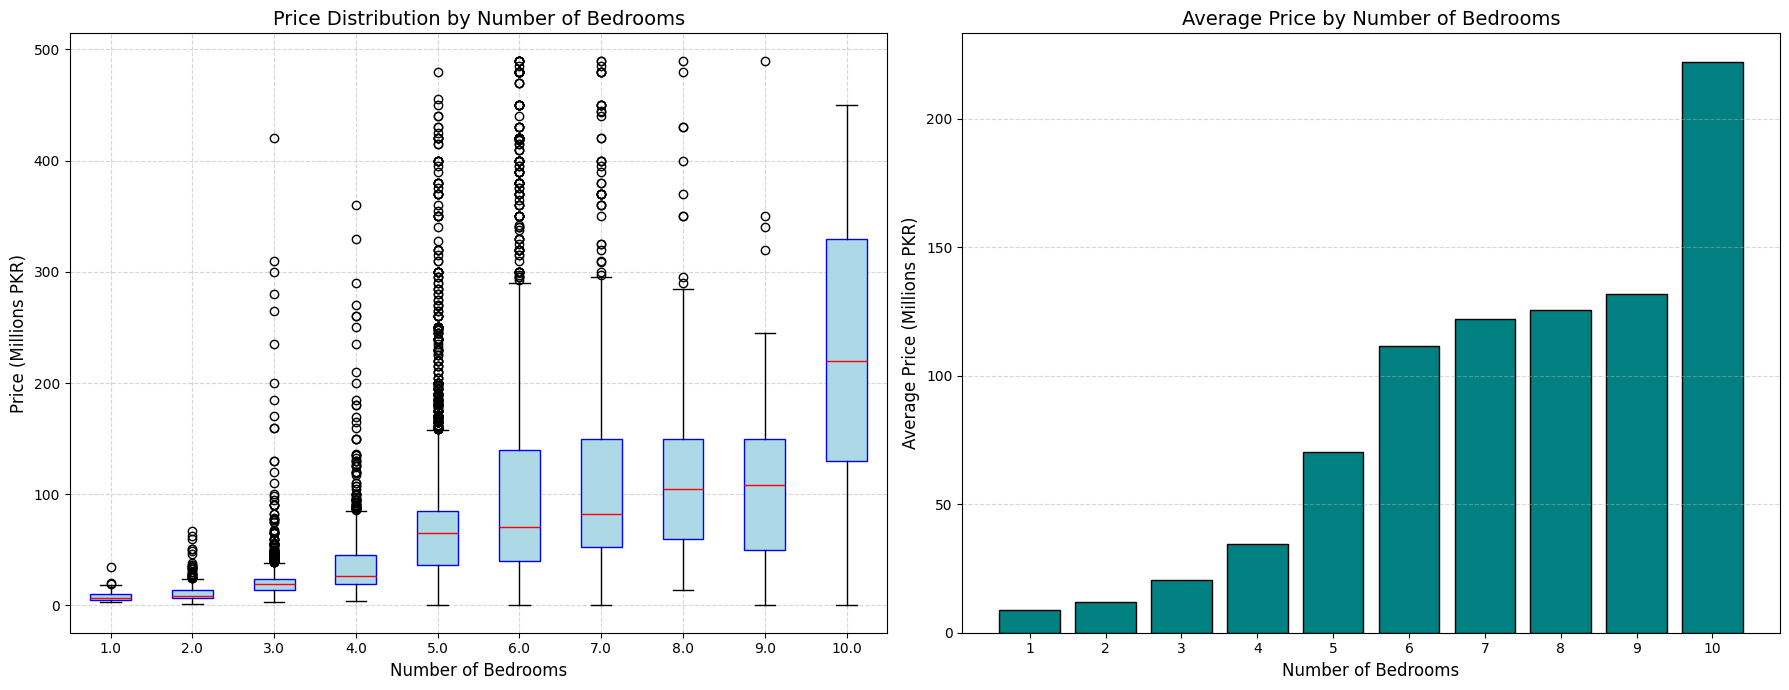

In [10]:
# Filter data to remove rows with missing prices or bedroom counts
# Also limit bedrooms to a reasonable range (e.g., 1 to 10) to avoid extreme outliers
bed_df = df[(df['Price_Millions_PKR'] > 0) &
            (df['Price_Millions_PKR'] < 500) &
            (df['Bedrooms_Numeric'] >= 1) &
            (df['Bedrooms_Numeric'] <= 10)].dropna(subset=['Price_Millions_PKR', 'Bedrooms_Numeric'])

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Boxplot of Price by Number of Bedrooms
# Group prices by bedroom count for the boxplot
bedroom_groups = [bed_df[bed_df['Bedrooms_Numeric'] == i]['Price_Millions_PKR'].values for i in sorted(bed_df['Bedrooms_Numeric'].unique())]
axes[0].boxplot(bedroom_groups, labels=sorted(bed_df['Bedrooms_Numeric'].unique()), patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='red'))
axes[0].set_title('Price Distribution by Number of Bedrooms', fontsize=14)
axes[0].set_xlabel('Number of Bedrooms', fontsize=12)
axes[0].set_ylabel('Price (Millions PKR)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Bar plot of Average Price by Number of Bedrooms
avg_prices = bed_df.groupby('Bedrooms_Numeric')['Price_Millions_PKR'].mean()
axes[1].bar(avg_prices.index.astype(int), avg_prices.values, color='teal', edgecolor='k')
axes[1].set_title('Average Price by Number of Bedrooms', fontsize=14)
axes[1].set_xlabel('Number of Bedrooms', fontsize=12)
axes[1].set_ylabel('Average Price (Millions PKR)', fontsize=12)
axes[1].set_xticks(sorted(bed_df['Bedrooms_Numeric'].unique()))
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Outlier Analysis using Interquartile Range (IQR)
We will statistically define outliers as any data point that lies more than $1.5 \times \text{IQR}$ below the first quartile ($Q_1$) or above the third quartile ($Q_3$).

--- Price (Millions PKR) Outlier Analysis ---
Q1 (25th percentile): 20.50
Q3 (75th percentile): 71.00
IQR: 50.50
Statistically normal range: [0.00, 146.75]
Number of outliers: 1135 out of 18249 entries (6.22%)

--- Area (Marla) Outlier Analysis ---
Q1 (25th percentile): 5.00
Q3 (75th percentile): 20.00
IQR: 15.00
Statistically normal range: [0.00, 42.50]
Number of outliers: 176 out of 18249 entries (0.96%)

--- Bedrooms Outlier Analysis ---
Q1 (25th percentile): 3.00
Q3 (75th percentile): 5.00
IQR: 2.00
Statistically normal range: [0.00, 8.00]
Number of outliers: 91 out of 17931 entries (0.51%)



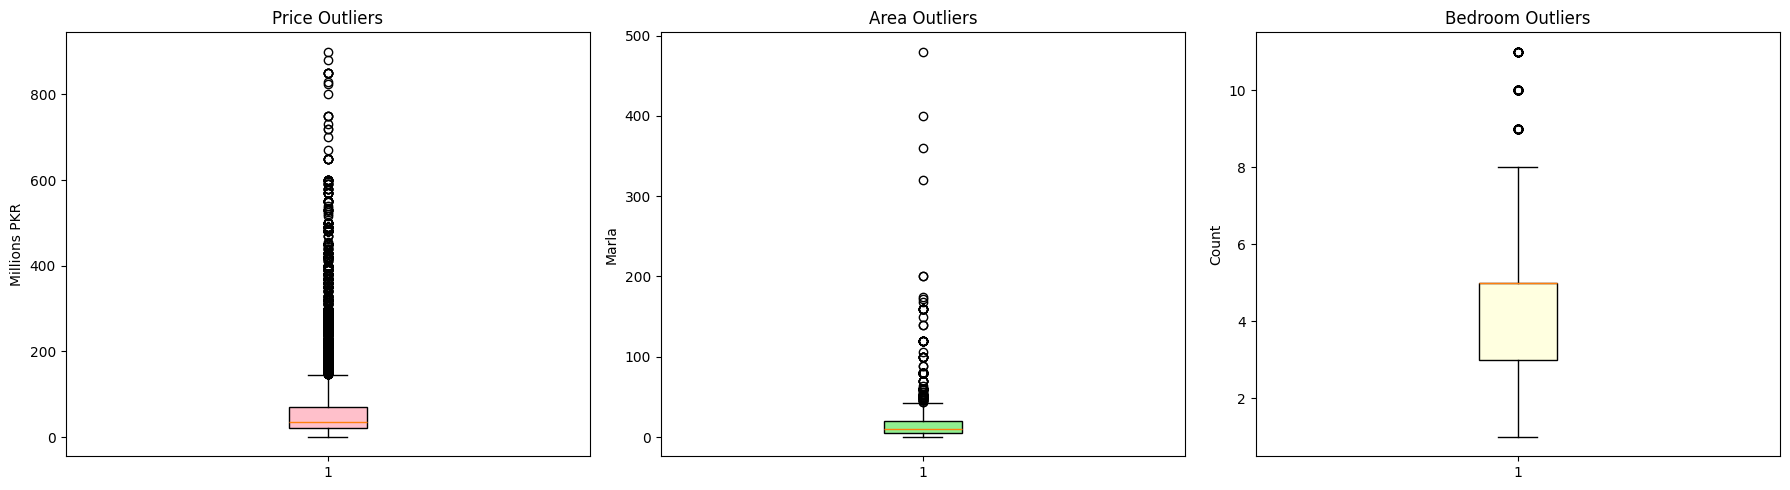

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

file_path = '/content/lahore_house_listings_zameen.csv'

# Safely load and clean the dataset if the file exists
if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    def clean_price(price_str):
        if pd.isna(price_str): return np.nan
        price_str = str(price_str).lower().strip()
        if 'crore' in price_str:
            val = float(re.findall(r'\d+\.?\d*', price_str)[0])
            return val * 10.0
        elif 'lakh' in price_str:
            val = float(re.findall(r'\d+\.?\d*', price_str)[0])
            return val * 0.1
        elif 'thousand' in price_str:
            val = float(re.findall(r'\d+\.?\d*', price_str)[0])
            return val * 0.001
        else:
            try:
                nums = re.findall(r'\d+\.?\d*', price_str)
                return float(nums[0]) / 1000000 if nums else np.nan
            except:
                return np.nan

    def clean_area(area_str):
        if pd.isna(area_str): return np.nan
        area_str = str(area_str).lower().strip()
        try:
            num = float(re.findall(r'\d+\.?\d*', area_str)[0])
            if 'kanal' in area_str:
                return num * 20.0
            return num
        except:
            return np.nan

    def clean_bedrooms(bed_str):
        if pd.isna(bed_str): return np.nan
        bed_str = str(bed_str).strip()
        try:
            match = re.search(r'\d+', bed_str)
            return int(match.group()) if match else np.nan
        except:
            return np.nan

    df['Price_Millions_PKR'] = df['Price'].apply(clean_price)
    df['Area_Marla'] = df['Area'].apply(clean_area)
    df['Bedrooms_Numeric'] = df['Bedrooms'].apply(clean_bedrooms)

    def analyze_outliers(series, name):
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers = series[(series < lower_bound) | (series > upper_bound)]
        print(f'--- {name} Outlier Analysis ---')
        print(f'Q1 (25th percentile): {q1:.2f}')
        print(f'Q3 (75th percentile): {q3:.2f}')
        print(f'IQR: {iqr:.2f}')
        print(f'Statistically normal range: [{max(0, lower_bound):.2f}, {upper_bound:.2f}]')
        print(f'Number of outliers: {len(outliers)} out of {len(series.dropna())} entries ({len(outliers)/len(series.dropna())*100:.2f}%)\n')

    analyze_outliers(df['Price_Millions_PKR'], 'Price (Millions PKR)')
    analyze_outliers(df['Area_Marla'], 'Area (Marla)')
    analyze_outliers(df['Bedrooms_Numeric'], 'Bedrooms')

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].boxplot(df['Price_Millions_PKR'].dropna(), patch_artist=True, boxprops=dict(facecolor='pink'))
    axes[0].set_title('Price Outliers')
    axes[0].set_ylabel('Millions PKR')

    axes[1].boxplot(df['Area_Marla'].dropna(), patch_artist=True, boxprops=dict(facecolor='lightgreen'))
    axes[1].set_title('Area Outliers')
    axes[1].set_ylabel('Marla')

    axes[2].boxplot(df['Bedrooms_Numeric'].dropna(), patch_artist=True, boxprops=dict(facecolor='lightyellow'))
    axes[2].set_title('Bedroom Outliers')
    axes[2].set_ylabel('Count')
    plt.tight_layout()
    plt.show()
else:
    print("Error: The file 'lahore_house_listings_zameen.csv' was not found in /content/.")
    print("Please upload or regenerate the dataset file, then run this cell again!")

### Removing Outliers
Using the IQR thresholds calculated above, we will filter the dataset to remove extreme values in `Price_Millions_PKR`, `Area_Marla`, and `Bedrooms_Numeric` to create a more robust set for modeling or descriptive analysis.

In [6]:
# Define the logical boundaries based on our IQR analysis
# If a column value is NaN, we'll keep it or let it pass so we don't accidentally lose too much missing data,
# or we can drop NaNs in these columns to have a fully clean working subset.

# Let's filter out values beyond our computed upper limits
price_upper = 146.75
area_upper = 42.50
bedrooms_upper = 8.0

# Create a filtered copy of the DataFrame
df_cleaned = df[
    ((df['Price_Millions_PKR'] >= 0) & (df['Price_Millions_PKR'] <= price_upper)) &
    ((df['Area_Marla'] >= 0) & (df['Area_Marla'] <= area_upper)) &
    ((df['Bedrooms_Numeric'].isna()) | ((df['Bedrooms_Numeric'] >= 0) & (df['Bedrooms_Numeric'] <= bedrooms_upper)))
].copy()

original_count = len(df)
cleaned_count = len(df_cleaned)
removed_count = original_count - cleaned_count

print(f"Original dataset size: {original_count} entries")
print(f"Cleaned dataset size (outliers removed): {cleaned_count} entries")
print(f"Removed entries: {removed_count} ({removed_count / original_count * 100:.2f}% of the dataset)")

# Display summary statistics of the cleaned data
display(df_cleaned[['Price_Millions_PKR', 'Area_Marla', 'Bedrooms_Numeric']].describe())

Original dataset size: 18249 entries
Cleaned dataset size (outliers removed): 17066 entries
Removed entries: 1183 (6.48% of the dataset)


,Price_Millions_PKR,Area_Marla,Bedrooms_Numeric
count,17066.000000,17066.000000,16772.000000
mean,43.254150,10.542916,4.306821
std,30.367612,7.042877,1.119935
min,0.000008,0.000000,1.000000
25%,20.000000,5.000000,3.000000
50%,32.900000,10.000000,4.000000
75%,64.000000,20.000000,5.000000
max,145.000000,42.000000,8.000000


### Removing Duplicate Records
We will check the cleaned dataset `df_cleaned` for any fully duplicate rows and drop them to ensure each listing is unique.

In [4]:
import pandas as pd
import numpy as np
import re

# 1. Load the dataset
file_path = '/content/lahore_house_listings_zameen.csv'
df = pd.read_csv(file_path)

# 2. Re-apply cleaning functions
def clean_price(price_str):
    if pd.isna(price_str): return np.nan
    price_str = str(price_str).lower().strip()
    if 'crore' in price_str:
        val = float(re.findall(r'\d+\.?\d*', price_str)[0])
        return val * 10.0
    elif 'lakh' in price_str:
        val = float(re.findall(r'\d+\.?\d*', price_str)[0])
        return val * 0.1
    elif 'thousand' in price_str:
        val = float(re.findall(r'\d+\.?\d*', price_str)[0])
        return val * 0.001
    else:
        try:
            nums = re.findall(r'\d+\.?\d*', price_str)
            return float(nums[0]) / 1000000 if nums else np.nan
        except:
            return np.nan

def clean_area(area_str):
    if pd.isna(area_str): return np.nan
    area_str = str(area_str).lower().strip()
    try:
        num = float(re.findall(r'\d+\.?\d*', area_str)[0])
        if 'kanal' in area_str:
            return num * 20.0
        return num
    except:
        return np.nan

def clean_bedrooms(bed_str):
    if pd.isna(bed_str): return np.nan
    bed_str = str(bed_str).strip()
    try:
        match = re.search(r'\d+', bed_str)
        return int(match.group()) if match else np.nan
    except:
        return np.nan

df['Price_Millions_PKR'] = df['Price'].apply(clean_price)
df['Area_Marla'] = df['Area'].apply(clean_area)
df['Bedrooms_Numeric'] = df['Bedrooms'].apply(clean_bedrooms)

# 3. Define the logical boundaries based on our IQR analysis
price_upper = 146.75
area_upper = 42.50
bedrooms_upper = 8.0

# 4. Filter out the outliers
df_cleaned = df[
    ((df['Price_Millions_PKR'] >= 0) & (df['Price_Millions_PKR'] <= price_upper)) &
    ((df['Area_Marla'] >= 0) & (df['Area_Marla'] <= area_upper)) &
    ((df['Bedrooms_Numeric'].isna()) | ((df['Bedrooms_Numeric'] >= 0) & (df['Bedrooms_Numeric'] <= bedrooms_upper)))
].copy()

# 5. Check and drop duplicate rows in the cleaned dataset
num_duplicates = df_cleaned.duplicated().sum()
print(f"Number of exact duplicate rows: {num_duplicates}")

if num_duplicates > 0:
    df_cleaned = df_cleaned.drop_duplicates().copy()
    print(f"Successfully removed {num_duplicates} duplicate rows.")
    print(f"New shape of df_cleaned: {df_cleaned.shape}")
else:
    print("No exact duplicate rows found!")

Number of exact duplicate rows: 0
No exact duplicate rows found!


### Categorical Encoding
We will now encode our categorical columns (`Furnished`, `Type`, and `General_Location`) so that they are ready for machine learning models.

* **`Furnished`**: Convert boolean to integer (0 or 1).
* **`Type`**: Use One-Hot Encoding (since there are very few unique property types).
* **`General_Location`**: Apply Frequency Encoding (to represent popularity) and Target Encoding (to represent the average price of properties in that specific locality).

In [6]:
import pandas as pd
import numpy as np

# 0. Define the neighborhood extraction function and regenerate the column
def extract_neighborhood(loc_str):
    if pd.isna(loc_str):
        return 'Unknown'
    parts = [p.strip() for p in str(loc_str).split(',')]
    for i, part in enumerate(parts):
        if 'lahore' in part.lower() and i > 0:
            return parts[i-1]
    return parts[0]

# Ensure both df_cleaned and df have General_Location defined
if 'General_Location' not in df_cleaned.columns:
    df_cleaned['General_Location'] = df_cleaned['Location'].apply(extract_neighborhood)

# Make a copy of df_cleaned for encoding
df_encoded = df_cleaned.copy()

# 1. Binary Encoding for 'Furnished'
df_encoded['Furnished_Encoded'] = df_encoded['Furnished'].astype(int)

# 2. One-Hot Encoding for 'Type'
# Drop 'Type' and join the new one-hot encoded columns
type_dummies = pd.get_dummies(df_encoded['Type'], prefix='Type', dtype=int)
df_encoded = pd.concat([df_encoded, type_dummies], axis=1)

# 3. Frequency Encoding for 'General_Location'
location_freq = df_encoded['General_Location'].value_counts() / len(df_encoded)
df_encoded['Location_Frequency_Encoded'] = df_encoded['General_Location'].map(location_freq)

# 4. Target (Mean Price) Encoding for 'General_Location'
location_target_mean = df_encoded.groupby('General_Location')['Price_Millions_PKR'].mean()
df_encoded['Location_Target_Encoded'] = df_encoded['General_Location'].map(location_target_mean)

# Display the newly created features alongside the original ones
preview_cols = [
    'General_Location', 'Location_Frequency_Encoded', 'Location_Target_Encoded',
    'Type', 'Furnished', 'Furnished_Encoded'
] + [col for col in type_dummies.columns]

display(df_encoded[preview_cols].head(10))
print(f"New dataset shape after encoding: {df_encoded.shape}")

,General_Location,Location_Frequency_Encoded,Location_Target_Encoded,Type,Furnished,Furnished_Encoded,Type_House
0,DHA Defence,0.301711,68.798019,House,True,1,1
1,Park View City,0.057073,20.836396,House,True,1,1
2,Park View City,0.057073,20.836396,House,True,1,1
3,DHA Defence,0.301711,68.798019,House,False,0,1
4,DHA Defence,0.301711,68.798019,House,True,1,1
5,Park View City,0.057073,20.836396,House,False,0,1
6,Valencia Housing Society,0.013887,64.497046,House,True,1,1
7,DHA Defence,0.301711,68.798019,House,True,1,1
9,College Road,0.004746,21.260494,House,False,0,1
10,Wagha Town,0.000234,17.000000,House,False,0,1


New dataset shape after encoding: (17066, 31)


### Feature Engineering: Property Age
We will create a new feature `Property_Age` from the `Built Year` column by subtracting the built year from the dataset's base year (2025).

In [8]:
# Calculate property age based on the reference year 2025
current_reference_year = 2025
df_encoded['Property_Age'] = current_reference_year - df_encoded['Built Year']

# Handle anomalies (e.g. negative ages due to future built years)
# Let's count how many negative age records exist first
negative_ages = (df_encoded['Property_Age'] < 0).sum()
print(f"Number of houses with negative ages (built in the future): {negative_ages}")

# Correcting negative ages to 0 (assuming they are brand new or under construction in 2025)
df_encoded.loc[df_encoded['Property_Age'] < 0, 'Property_Age'] = 0

# Let's inspect the corrected statistics
print("\nProperty Age Summary Statistics (After Handling Anomalies):")
display(df_encoded['Property_Age'].describe())

# Let's display a preview of the built year alongside the newly calculated age
display(df_encoded[['Title', 'Built Year', 'Property_Age']].dropna().head(10))

Number of houses with negative ages (built in the future): 78

Property Age Summary Statistics (After Handling Anomalies):


,Property_Age
count,12577.000000
mean,2.233919
std,4.481211
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,50.000000


,Title,Built Year,Property_Age
0,ACTUALLY 25 MARLA DOUBLE UNIT LUXURIOUS & GRAC...,2024.0,1.0
1,3 Years Installment Plan Luxury Brand New Hous...,2012.0,13.0
2,5 Marla Luxury House In Rose Block Of Park-Vie...,2025.0,0.0
3,Full Basement 1 kanal Brand New Luxury House N...,2024.0,1.0
4,1 Kanal Dream Home With Private Pool In DHA Ph...,2024.0,1.0
6,Ultra Modern - 10 Marla Brand New House - Prim...,2025.0,0.0
7,01 KANAL MODREN HOUSE ON 150 FEET MAIN ROAD DH...,2024.0,1.0
10,5 Marla Beautiful House For Sale In Eastern Ho...,2023.0,2.0
11,5 Marla Good Condition Carefully Used House Fo...,2012.0,13.0
13,Most Wanted 10-Marla Luxurious Modern House Fo...,2025.0,0.0


### Train-Test Split
We will now set up our feature matrix ($X$) and target vector ($y$), handle missing values via imputation, and split our data into training (80%) and testing (20%) sets.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# 1. Define target column and select numeric/encoded features
target_col = 'Price_Millions_PKR'

# Identify non-numeric, raw metadata, or unencoded columns to drop
cols_to_drop = [
    'Title', 'Location', 'Type', 'Price', 'Area', 'Bedrooms', 'Bathrooms',
    'Purpose', 'Date Posted', 'Link', 'General_Location', 'Furnished', 'Built Year', target_col
]

# Filter features
feature_cols = [col for col in df_encoded.columns if col not in cols_to_drop]
X = df_encoded[feature_cols].copy()
y = df_encoded[target_col].copy()

# 2. Impute missing values (e.g., in Property_Age or Bedrooms_Numeric if any exist)
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 3. Perform Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)

# Print split statistics
print("Selected Features for Training:")
print(list(X.columns))
print(f"\nFull feature matrix shape: {X_imputed.shape}")
print(f"Training set shape: {X_train.shape} (Features) | {y_train.shape} (Target)")
print(f"Testing set shape:  {X_test.shape} (Features) | {y_test.shape} (Target)")

Selected Features for Training:
['Kitchens', 'Store Rooms', 'Servant Quarters', 'Gym', 'Study Room', 'Drawing Room', 'Dining Room', 'Lawn/Garden', 'Swimming Pool', 'Electricity Backup', 'Lounge/Sitting Room', 'Area_Marla', 'Bedrooms_Numeric', 'Furnished_Encoded', 'Type_House', 'Location_Frequency_Encoded', 'Location_Target_Encoded', 'Property_Age']

Full feature matrix shape: (17066, 18)
Training set shape: (13652, 18) (Features) | (13652,) (Target)
Testing set shape:  (3414, 18) (Features) | (3414,) (Target)


### Model Training and Evaluation
We will train three regression models to predict property prices in Millions PKR:
1. **Linear Regression**
2. **Decision Tree Regressor**
3. **Random Forest Regressor**

We will evaluate their performance on the test set using standard regression metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time

# Initialize the models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42, max_depth=10),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=100, max_depth=12, n_jobs=-1)
}

# Dictionary to store performance results
results = {}

# Train and evaluate each model
for name, model in models.items():
    print(f"Training {name}...")
    start_time = time.time()
    model.fit(X_train, y_train)
    elapsed_time = time.time() - start_time

    # Predict
    y_pred = model.predict(X_test)

    # Evaluate metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results[name] = {
        'MAE (Millions PKR)': round(mae, 2),
        'RMSE (Millions PKR)': round(rmse, 2),
        'R2 Score': round(r2, 4),
        'Train Time (sec)': round(elapsed_time, 2)
    }

# Display the results table
results_df = pd.DataFrame(results).T
display(results_df)

Training Linear Regression...
Training Decision Tree...
Training Random Forest...


,MAE (Millions PKR),RMSE (Millions PKR),R2 Score,Train Time (sec)
Linear Regression,8.13,12.10,0.8336,0.09
Decision Tree,7.01,11.53,0.8489,0.10
Random Forest,6.49,10.60,0.8722,2.76


### Interactive Property Price Predictor
Below is an interactive dashboard where you can input specific property details and receive an instant price estimation from our trained **Random Forest** model.

In [1]:
import os
import re
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
import ipywidgets as widgets
from IPython.display import display, clear_output

file_path = '/content/lahore_house_listings_zameen.csv'

if not os.path.exists(file_path):
    print("❌ ERROR: 'lahore_house_listings_zameen.csv' was not found in /content/")
    print("👉 Please click the file folder icon on the left panel in Colab, upload the dataset file, and then run this cell again!")
else:
    # 1. Load and clean dataset
    df_raw = pd.read_csv(file_path)

    # Standard cleaning functions
    def clean_price(price_str):
        if pd.isna(price_str): return np.nan
        price_str = str(price_str).lower().strip()
        if 'crore' in price_str:
            val = float(re.findall(r'\d+\.?\d*', price_str)[0])
            return val * 10.0
        elif 'lakh' in price_str:
            val = float(re.findall(r'\d+\.?\d*', price_str)[0])
            return val * 0.1
        elif 'thousand' in price_str:
            val = float(re.findall(r'\d+\.?\d*', price_str)[0])
            return val * 0.001
        else:
            try:
                nums = re.findall(r'\d+\.?\d*', price_str)
                return float(nums[0]) / 1000000 if nums else np.nan
            except:
                return np.nan

    def clean_area(area_str):
        if pd.isna(area_str): return np.nan
        area_str = str(area_str).lower().strip()
        try:
            num = float(re.findall(r'\d+\.?\d*', area_str)[0])
            if 'kanal' in area_str:
                return num * 20.0
            return num
        except:
            return np.nan

    def clean_bedrooms(bed_str):
        if pd.isna(bed_str): return np.nan
        bed_str = str(bed_str).strip()
        try:
            match = re.search(r'\d+', bed_str)
            return int(match.group()) if match else np.nan
        except:
            return np.nan

    def extract_neighborhood(loc_str):
        if pd.isna(loc_str): return 'Unknown'
        parts = [p.strip() for p in str(loc_str).split(',')]
        for i, part in enumerate(parts):
            if 'lahore' in part.lower() and i > 0:
                return parts[i-1]
        return parts[0]

    # Preprocess and filter outliers
    df_raw['Price_Millions_PKR'] = df_raw['Price'].apply(clean_price)
    df_raw['Area_Marla'] = df_raw['Area'].apply(clean_area)
    df_raw['Bedrooms_Numeric'] = df_raw['Bedrooms'].apply(clean_bedrooms)
    df_raw['General_Location'] = df_raw['Location'].apply(extract_neighborhood)

    price_upper = 146.75
    area_upper = 42.50
    bedrooms_upper = 8.0

    df_cleaned = df_raw[
        ((df_raw['Price_Millions_PKR'] >= 0) & (df_raw['Price_Millions_PKR'] <= price_upper)) &
        ((df_raw['Area_Marla'] >= 0) & (df_raw['Area_Marla'] <= area_upper)) &
        ((df_raw['Bedrooms_Numeric'].isna()) | ((df_raw['Bedrooms_Numeric'] >= 0) & (df_raw['Bedrooms_Numeric'] <= bedrooms_upper)))
    ].copy()

    # Encoding
    df_encoded = df_cleaned.copy()
    df_encoded['Furnished_Encoded'] = df_encoded['Furnished'].astype(int)
    type_dummies = pd.get_dummies(df_encoded['Type'], prefix='Type', dtype=int)
    df_encoded = pd.concat([df_encoded, type_dummies], axis=1)
    if 'Type_House' not in df_encoded.columns:
        df_encoded['Type_House'] = 0

    location_freq = df_encoded['General_Location'].value_counts() / len(df_encoded)
    df_encoded['Location_Frequency_Encoded'] = df_encoded['General_Location'].map(location_freq)

    location_target_mean = df_encoded.groupby('General_Location')['Price_Millions_PKR'].mean()
    df_encoded['Location_Target_Encoded'] = df_encoded['General_Location'].map(location_target_mean)

    # Age
    df_encoded['Property_Age'] = 2025 - df_encoded['Built Year']
    df_encoded.loc[df_encoded['Property_Age'] < 0, 'Property_Age'] = 0

    # Drop unneeded features
    cols_to_drop = [
        'Title', 'Location', 'Type', 'Price', 'Area', 'Bedrooms', 'Bathrooms',
        'Purpose', 'Date Posted', 'Link', 'General_Location', 'Furnished', 'Built Year', 'Price_Millions_PKR'
    ]
    feature_cols = [col for col in df_encoded.columns if col not in cols_to_drop]
    X = df_encoded[feature_cols].copy()
    y = df_encoded['Price_Millions_PKR'].copy()

    # Impute missing features
    imputer = SimpleImputer(strategy='median')
    X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

    # Train the Random Forest Model
    best_model = RandomForestRegressor(random_state=42, n_estimators=100, max_depth=12, n_jobs=-1)
    best_model.fit(X_imputed, y)

    # 2. Build Interactive Widgets
    area_widget = widgets.FloatSlider(value=10.0, min=1.0, max=40.0, step=0.5, description='Area (Marla):')
    bedrooms_widget = widgets.IntSlider(value=4, min=1, max=8, description='Bedrooms:')
    age_widget = widgets.IntSlider(value=1, min=0, max=50, description='Property Age:')

    unique_locations = sorted(df_cleaned['General_Location'].unique())
    location_widget = widgets.Dropdown(options=unique_locations, value='DHA Defence' if 'DHA Defence' in unique_locations else unique_locations[0], description='Location:')
    type_widget = widgets.Dropdown(options=['House', 'Flat/Other'], value='House', description='Property Type:')
    furnished_widget = widgets.Checkbox(value=False, description='Is Furnished')
    kitchens_widget = widgets.IntSlider(value=1, min=1, max=3, description='Kitchens:')
    lawn_widget = widgets.Checkbox(value=False, description='Has Lawn/Garden')
    pool_widget = widgets.Checkbox(value=False, description='Has Pool')

    predict_button = widgets.Button(description='Predict Price', button_style='success')
    output_area = widgets.Output()

    def make_prediction(b):
        with output_area:
            clear_output()

            input_dict = {col: 0.0 for col in X_imputed.columns}

            input_dict['Area_Marla'] = float(area_widget.value)
            input_dict['Bedrooms_Numeric'] = float(bedrooms_widget.value)
            input_dict['Property_Age'] = float(age_widget.value)
            input_dict['Kitchens'] = float(kitchens_widget.value)

            input_dict['Furnished_Encoded'] = 1.0 if furnished_widget.value else 0.0
            input_dict['Type_House'] = 1.0 if type_widget.value == 'House' else 0.0
            input_dict['Lawn/Garden'] = 1.0 if lawn_widget.value else 0.0
            input_dict['Swimming Pool'] = 1.0 if pool_widget.value else 0.0

            selected_loc = location_widget.value
            freq_val = location_freq.get(selected_loc, location_freq.mean())
            target_val = location_target_mean.get(selected_loc, location_target_mean.mean())

            input_dict['Location_Frequency_Encoded'] = float(freq_val)
            input_dict['Location_Target_Encoded'] = float(target_val)

            input_df = pd.DataFrame([input_dict])[X_imputed.columns]
            predicted_price = best_model.predict(input_df)[0]

            print(f"\n✨ Estimated Price: {predicted_price:.2f} Million PKR")
            print(f"   (Approximately {(predicted_price / 10):.2f} Crore PKR)")

    predict_button.on_click(make_prediction)

    left_box = widgets.VBox([location_widget, type_widget, area_widget, bedrooms_widget, age_widget])
    right_box = widgets.VBox([kitchens_widget, furnished_widget, lawn_widget, pool_widget])

    print("—"*50)
    print(" ENTER PROPERTY PARAMETERS FOR PRICE ESTIMATION ")
    print("—"*50)
    display(widgets.HBox([left_box, right_box]))
    display(predict_button)
    display(output_area)

——————————————————————————————————————————————————
 ENTER PROPERTY PARAMETERS FOR PRICE ESTIMATION 
——————————————————————————————————————————————————


Button(button_style='success', description='Predict Price', style=ButtonStyle())

Output()

In [2]:
import joblib

# Prepare the metadata and artifacts required for inference
model_artifacts = {
    'model': best_model,
    'features': feature_cols,
    'imputer': imputer,
    'location_freq': location_freq,
    'location_target_mean': location_target_mean
}

# Save artifacts to a single joblib file
artifact_path = '/content/lahore_house_model.joblib'
joblib.dump(model_artifacts, artifact_path)

print(f"🎉 Success! Model and preprocessing artifacts successfully saved to: {artifact_path}")
print("👉 You can download this file from your Colab files panel to use in your local FastAPI backend project.")

🎉 Success! Model and preprocessing artifacts successfully saved to: /content/lahore_house_model.joblib
👉 You can download this file from your Colab files panel to use in your local FastAPI backend project.
